<a href="https://colab.research.google.com/github/JaquelinedeJesus/Simulaci-n-2/blob/main/Integral%20estoc%C3%A1stica%20Actividad2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
import random as r
import matplotlib.pyplot as plt

In [9]:
a=0
b=1
n=1000

In [10]:
def brown(T,L):
  lista=[]
  w0=0
  dt=T/L
  for i in range (1,L):
    dw=np.random.normal(0,1)
    w_1=w0+np.sqrt(dt)*dw
    lista.append(w_1)
    w0=w_1
  lista.insert(0,0)
  return lista

In [11]:
def integral(a,b,n):
    inte=0
    t=np.linspace(a,b,n)
    t=t.tolist()
    B=brown(b,n)
    for i in range (1,n):
      inte+= B[i-1]*(t[i]-t[i-1])
    return inte

In [12]:
integral(0,1,100)


np.float64(0.6960688237516991)

In [17]:
plt.plot(B, color="#FF0000")

NameError: name 'B' is not defined

In [18]:
valores=[]
for i in range(1,1000):
  avr=integral(0,1,100)
  m=avr/i
  valores.append(m)

In [19]:
np.mean(valores)

np.float64(-0.000498261176322853)

In [20]:
np.var(valores)

np.float64(0.0008167617443268306)

In [21]:
i

999

# **Actividad 2 - Ejercicio 2**

RESULTADOS DE LA SIMULACIÓN (t = 1)
Trayectorias (N): 100,000 | Pasos (L): 2000 | dt: 0.0005

Esperanza teórica (t^2 / 2):  0.500000
Esperanza simulada:           0.498137  (Error rel.: 0.373%)

Varianza teórica (t^4 / 3):   0.333333
Varianza simulada:            0.328861  (Error rel.: 1.342%)


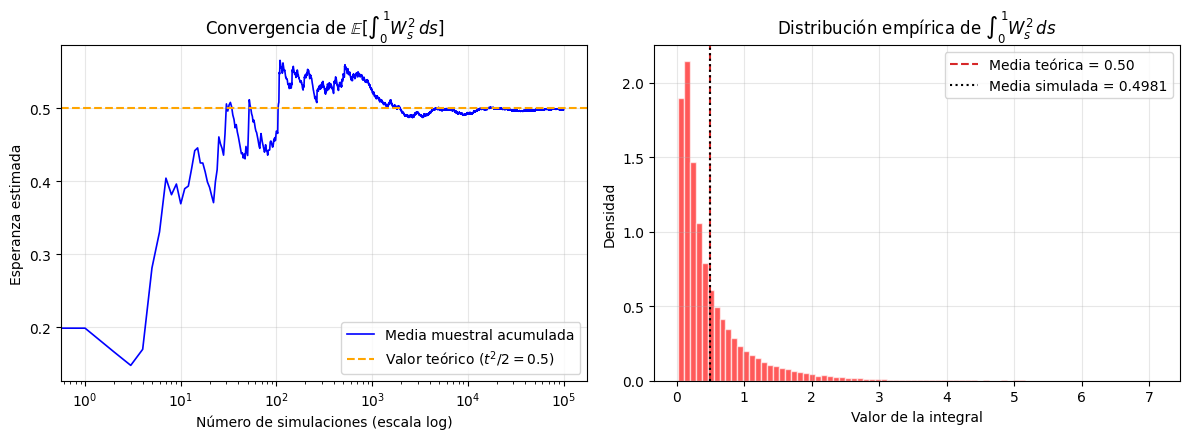

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parámetros de la simulación
rng = np.random.default_rng(123)
T = 1.0
L = 2000
dt = T / L
N_sim = 100_000

# 2. Simulación de trayectorias del Movimiento Browniano estándar W_t
dW = rng.normal(loc=0.0, scale=np.sqrt(dt), size=(N_sim, L))

# Construcción de W(t_i) para i = 0, 1, ..., L con W(0) = 0
W = np.zeros((N_sim, L + 1))
W[:, 1:] = np.cumsum(dW, axis=1)

# 3. Aproximación de la integral \int_0^1 W_s^2 ds por sumas de Riemann
I_riemann_izq = np.sum(W[:, :-1]**2 * dt, axis=1)

I_trapecio = np.sum(0.5 * (W[:, :-1]*2 + W[:, 1:]*2) * dt, axis=1)

# 4. Valores teóricos del Ejercicio 1 evaluados en t = 1
esperanza_teorica = (T**2) / 2.0   # t^2 / 2 = 0.5
varianza_teorica = (T**4) / 3.0    # t^4 / 3 = 0.333333...

# 5. Estimadores muestrales
esperanza_sim = np.mean(I_riemann_izq)
varianza_sim = np.var(I_riemann_izq, ddof=1)

err_rel_esp = abs(esperanza_sim - esperanza_teorica) / esperanza_teorica * 100
err_rel_var = abs(varianza_sim - varianza_teorica) / varianza_teorica * 100

print("RESULTADOS DE LA SIMULACIÓN (t = 1)")
print(f"Trayectorias (N): {N_sim:,} | Pasos (L): {L} | dt: {dt}\n")

print(f"Esperanza teórica (t^2 / 2):  {esperanza_teorica:.6f}")
print(f"Esperanza simulada:           {esperanza_sim:.6f}  (Error rel.: {err_rel_esp:.3f}%)\n")

print(f"Varianza teórica (t^4 / 3):   {varianza_teorica:.6f}")
print(f"Varianza simulada:            {varianza_sim:.6f}  (Error rel.: {err_rel_var:.3f}%)")

# 6. Visualización: Convergencia de la media y distribución de \int_0^1 W_s^2 ds
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel izquierdo: Convergencia de la media acumulada
medias_acum = np.cumsum(I_riemann_izq) / np.arange(1, N_sim + 1)
axes[0].plot(medias_acum, color="#0000FF", lw=1.2, label="Media muestral acumulada")
axes[0].axhline(esperanza_teorica, color="#FFA500", linestyle="--", lw=1.5,
                label=f"Valor teórico ($t^2/2 = {esperanza_teorica}$)")
axes[0].set_xscale("log")
axes[0].set_title("Convergencia de $\\mathbb{E}[\\int_0^1 W_s^2\\,ds]$")
axes[0].set_xlabel("Número de simulaciones (escala log)")
axes[0].set_ylabel("Esperanza estimada")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel derecho: Histograma de las realizaciones de la integral
axes[1].hist(I_riemann_izq, bins=80, density=True, color="#FF0000", alpha=0.65, edgecolor="white")
axes[1].axvline(esperanza_teorica, color="#d62728", linestyle="--", lw=1.5,
                label=f"Media teórica = {esperanza_teorica:.2f}")
axes[1].axvline(esperanza_sim, color="black", linestyle=":", lw=1.5,
                label=f"Media simulada = {esperanza_sim:.4f}")
axes[1].set_title("Distribución empírica de $\\int_0^1 W_s^2\\,ds$")
axes[1].set_xlabel("Valor de la integral")
axes[1].set_ylabel("Densidad")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()